# Optimizers in Deep Learning — Part 3: RMSprop, Adadelta & Adam

**Series so far:**
1. GD, SGD, Mini-Batch GD ✅ (covered)
2. Momentum, NAG ✅ (covered)
3. Adagrad ✅ (covered)
4. **RMSprop, Adadelta, Adam ← this notebook**

**Recap — where we left off:** Adagrad gives each parameter its own adaptive learning rate by dividing by the *cumulative sum* of squared past gradients. This fixes the "one-learning-rate-fits-all" problem, but that cumulative sum only ever grows — so the effective learning rate keeps shrinking and can vanish, stalling training.

The three optimizers below all fix this **vanishing learning rate** problem, each in a slightly different way.

## 0. Common Setup

We reuse the same toy dataset and model architecture across all optimizers so the comparison is fair.

In [ ]:
# Common imports
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Toy binary classification dataset (same as used for earlier optimizers)
np.random.seed(42)
X = np.random.randn(1000, 20)
y = (np.sum(X[:, :5], axis=1) > 0).astype(int)

def build_model():
    """Fresh model each time so weight initialization doesn't bias the comparison."""
    model = keras.Sequential([
        layers.Dense(16, activation='relu', input_shape=(20,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

## 1. RMSprop (Root Mean Square Propagation)

**Fix applied to Adagrad:** instead of a cumulative *sum* of all past squared gradients (which only grows), RMSprop uses an **exponentially decaying moving average** of squared gradients. Old gradients gradually "fade out" instead of piling up forever.

$$E[g^2]_t = \beta \, E[g^2]_{t-1} + (1-\beta)\,(\nabla_\theta J(\theta))^2$$

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{E[g^2]_t + \epsilon}} \cdot \nabla_\theta J(\theta)$$

- $\beta$ (decay rate, typically **0.9**) controls how quickly old squared-gradients are forgotten.
- Because it's a *moving average* rather than a running sum, $E[g^2]_t$ can go up **or** down as gradient magnitudes change — the effective learning rate no longer decays to zero.
- Still per-parameter adaptive, like Adagrad — just without the vanishing-LR flaw.

**Analogy:** Adagrad remembers *everything* that ever happened (and gets more cautious forever). RMSprop has a *short-term memory* — it stays responsive to how steep the loss surface is *right now*.

In [ ]:
# RMSprop optimizer
model_rmsprop = build_model()
model_rmsprop.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=0.01,
        rho=0.9,          # decay rate (beta) for the moving average of squared gradients
        epsilon=1e-7       # numerical stability constant
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_rmsprop = model_rmsprop.fit(X, y, batch_size=32, epochs=50, verbose=1)
print("Final RMSprop loss:", history_rmsprop.history['loss'][-1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7550 - loss: 0.4829
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9390 - loss: 0.1580
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9790 - loss: 0.0715
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9830 - loss: 0.0435
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9910 - loss: 0.0284
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9940 - loss: 0.0205
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9910 - loss: 0.0235
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9980 - loss: 0.0096
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9980 - loss: 0.0077     
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9970 - loss: 0.0097
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9980 - loss: 0.0062
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9980

## 2. Adadelta

**Fix applied to Adagrad (a second approach):** Adadelta starts from the same idea as RMSprop — a decaying average of squared gradients instead of a running sum — but goes one step further and **removes the need to manually set a learning rate $\eta$ at all**.

It keeps two running averages instead of one:
1. Decaying average of squared **gradients** (same as RMSprop): $E[g^2]_t$
2. Decaying average of squared **parameter updates**: $E[\Delta\theta^2]_t$

$$\Delta\theta_t = -\frac{\sqrt{E[\Delta\theta^2]_{t-1} + \epsilon}}{\sqrt{E[g^2]_t + \epsilon}} \cdot \nabla_\theta J(\theta)$$

$$\theta_{t+1} = \theta_t + \Delta\theta_t$$

- The units of the update automatically match the units of the parameter (a subtle but real issue with GD/SGD/Momentum/RMSprop, where the update's units depend on the gradient's units, not the parameter's).
- In practice, most implementations (including Keras) still expose a `learning_rate` argument as a global scaling knob, but the algorithm was originally designed to work well even with it fixed at 1.0.

**Analogy:** RMSprop adapts the learning rate based on *how big the gradients have been*. Adadelta additionally adapts based on *how big the updates themselves have been* — so it's self-calibrating and less sensitive to the initial learning-rate choice.

In [ ]:
# Adadelta optimizer
model_adadelta = build_model()
model_adadelta.compile(
    optimizer=keras.optimizers.Adadelta(
        learning_rate=1.0,   # global scaling knob -- Adadelta is designed to work even at 1.0
        rho=0.95,             # decay rate for both running averages
        epsilon=1e-7
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_adadelta = model_adadelta.fit(X, y, batch_size=32, epochs=50, verbose=0)
print("Final Adadelta loss:", history_adadelta.history['loss'][-1])

Final Adadelta loss: 0.00672061275690794


## 3. Adam (Adaptive Moment Estimation)

**The combination optimizer.** Adam merges the two separate ideas we've built up across this whole series:

- **Momentum** → keep a decaying average of the gradient itself (the "first moment", direction/velocity)
- **RMSprop** → keep a decaying average of the squared gradient (the "second moment", magnitude, for per-parameter scaling)

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t \quad \text{(momentum-like term)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2 \quad \text{(RMSprop-like term)}$$

Both are initialized at 0, which biases them toward 0 early in training — so Adam applies a **bias correction**:

$$\hat{m}_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1-\beta_2^t}$$

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t}+\epsilon}\,\hat{m}_t$$

- $\beta_1$ (typically **0.9**) → decay rate for the momentum term
- $\beta_2$ (typically **0.999**) → decay rate for the squared-gradient (RMSprop) term
- Gets **both** benefits at once: smoothed, momentum-driven direction *and* per-parameter adaptive step size.

**Why it's the default choice today:** it's robust to the initial learning-rate choice, works well with sparse gradients (inherited from the RMSprop/Adagrad lineage), and its momentum term smooths out the noisy path that plain SGD/RMSprop can take.

In [ ]:
# Adam optimizer
model_adam = build_model()
model_adam.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.01,
        beta_1=0.9,      # decay rate for the momentum-like term (1st moment)
        beta_2=0.999,    # decay rate for the RMSprop-like term (2nd moment)
        epsilon=1e-7
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_adam = model_adam.fit(X, y, batch_size=32, epochs=50, verbose=1)
print("Final Adam loss:", history_adam.history['loss'][-1])

Epoch 1/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7650 - loss: 0.4898
Epoch 2/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9570 - loss: 0.1444
Epoch 3/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9810 - loss: 0.0570
Epoch 4/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9920 - loss: 0.0359
Epoch 5/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9930 - loss: 0.0235
Epoch 6/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9980 - loss: 0.0146
Epoch 7/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9990 - loss: 0.0093
Epoch 8/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0056
Epoch 9/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0045
Epoch 10/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0034
Epoch 11/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 12/50
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - lo

## 4. Full Optimizer Family — Comparison Table

| Optimizer | Adapts direction (momentum)? | Adapts per-parameter LR? | Fixes vanishing LR? | Needs manual LR tuning? |
|---|---|---|---|---|
| SGD | No | No | — | Yes |
| Momentum | Yes | No | — | Yes |
| NAG | Yes (look-ahead) | No | — | Yes |
| Adagrad | No | Yes | **No — this is its flaw** | Less, but still decays to 0 |
| RMSprop | No | Yes | Yes (decaying avg) | Yes |
| Adadelta | No | Yes | Yes (decaying avg) | **Barely — self-calibrating** |
| Adam | **Yes** | **Yes** | Yes | Yes (but robust to choice) |

**Teaching narrative for this whole series:**
`SGD → Momentum/NAG (fix: oscillation/direction) → Adagrad (fix: per-parameter LR) → RMSprop/Adadelta (fix: Adagrad's vanishing LR) → Adam (combine momentum + adaptive LR into one optimizer)`

## 5. Visualizing Convergence

Plotting the loss curves side by side makes the differences concrete.

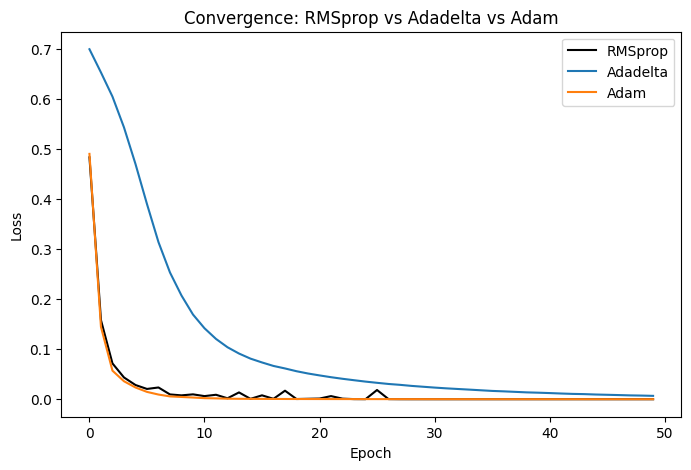

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history_rmsprop.history['loss'], label='RMSprop', color = 'black')
plt.plot(history_adadelta.history['loss'], label='Adadelta')
plt.plot(history_adam.history['loss'], label='Adam')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Convergence: RMSprop vs Adadelta vs Adam')
plt.legend()
plt.show()

### 📌 Observations

- **Adam** typically converges fastest and most smoothly on this kind of problem — it's why it's the default starting choice in most modern deep learning code.
- **Adadelta** often looks *slower* in early epochs on default settings, because it's deliberately self-calibrating rather than taking large early steps like Adam.
- **RMSprop** is a strong, simple baseline — closely related to Adam minus the momentum term.
- None of these three should show the "flatlining" behavior Adagrad showed in the previous notebook — that's the visual proof the vanishing-LR problem has been fixed.
- In practice: **start with Adam** for most problems; reach for RMSprop for some RNN-heavy tasks (a historical convention); Adadelta is rarely used today but is good to know conceptually.

## Use

1. Image -> CNN    -> `SGD`
2. NLP -> RNN/ANN  -> `Adam`
3. TSA -> LSTM/GRU -> `RMSProp`